In [159]:
import pandas as pd

In [160]:
train = pd.read_csv("telecom_customer_churn.csv")
train.head()

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [161]:
# Menampilkan ringkasan informasi dari dataset
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   str    
 1   Gender                             7043 non-null   str    
 2   Age                                7043 non-null   int64  
 3   Married                            7043 non-null   str    
 4   Number of Dependents               7043 non-null   int64  
 5   City                               7043 non-null   str    
 6   Zip Code                           7043 non-null   int64  
 7   Latitude                           7043 non-null   float64
 8   Longitude                          7043 non-null   float64
 9   Number of Referrals                7043 non-null   int64  
 10  Tenure in Months                   7043 non-null   int64  
 11  Offer                              3166 non-null   str    
 12  Pho

In [162]:
# Menampilkan statistik deskriptif dari dataset
train.describe(include="all")

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
count,7043,7043,7043.000000,7043,7043.000000,7043,7043.000000,7043.000000,7043.000000,7043.000000,...,7043,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043,1869,1869
unique,7043,2,NaN,2,NaN,1106,NaN,NaN,NaN,NaN,...,3,NaN,NaN,NaN,NaN,NaN,NaN,3,5,20
top,0002-ORFBO,Male,NaN,No,NaN,Los Angeles,NaN,NaN,NaN,NaN,...,Bank Withdrawal,NaN,NaN,NaN,NaN,NaN,NaN,Stayed,Competitor,Competitor had better devices
freq,1,3555,NaN,3641,NaN,293,NaN,NaN,NaN,NaN,...,3909,NaN,NaN,NaN,NaN,NaN,NaN,4720,841,313
mean,NaN,NaN,46.509726,NaN,0.468692,NaN,93486.070567,36.197455,-119.756684,1.951867,...,NaN,63.596131,2280.381264,1.962182,6.860713,749.099262,3034.379056,NaN,NaN,NaN
std,NaN,NaN,16.750352,NaN,0.962802,NaN,1856.767505,2.468929,2.154425,3.001199,...,NaN,31.204743,2266.220462,7.902614,25.104978,846.660055,2865.204542,NaN,NaN,NaN
min,NaN,NaN,19.000000,NaN,0.000000,NaN,90001.000000,32.555828,-124.301372,0.000000,...,NaN,-10.000000,18.800000,0.000000,0.000000,0.000000,21.360000,NaN,NaN,NaN
25%,NaN,NaN,32.000000,NaN,0.000000,NaN,92101.000000,33.990646,-121.788090,0.000000,...,NaN,30.400000,400.150000,0.000000,0.000000,70.545000,605.610000,NaN,NaN,NaN
50%,NaN,NaN,46.000000,NaN,0.000000,NaN,93518.000000,36.205465,-119.595293,0.000000,...,NaN,70.050000,1394.550000,0.000000,0.000000,401.440000,2108.640000,NaN,NaN,NaN
75%,NaN,NaN,60.000000,NaN,0.000000,NaN,95329.000000,38.161321,-117.969795,3.000000,...,NaN,89.750000,3786.600000,0.000000,0.000000,1191.100000,4801.145000,NaN,NaN,NaN


In [163]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

Offer                                3877
Avg Monthly Long Distance Charges     682
Multiple Lines                        682
Internet Type                        1526
Avg Monthly GB Download              1526
Online Security                      1526
Online Backup                        1526
Device Protection Plan               1526
Premium Tech Support                 1526
Streaming TV                         1526
Streaming Movies                     1526
Streaming Music                      1526
Unlimited Data                       1526
Churn Category                       5174
Churn Reason                         5174
dtype: int64

In [164]:
less = missing_values[missing_values < (len(train) * 0.75)].index
over = missing_values[missing_values >= (len(train) * 0.75)].index

In [165]:
print("Kolom yang dihapus:")
print(over.tolist())

Kolom yang dihapus:
[]


In [166]:
# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

In [167]:
# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = train[less].select_dtypes(include=['str']).columns

for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

In [168]:
df = train

In [169]:
print("Jumlah data awal :", len(train))
print("Jumlah data df   :", len(df))
print("Data yang hilang :", len(train) - len(df))

Jumlah data awal : 7043
Jumlah data df   : 7043
Data yang hilang : 0


In [170]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

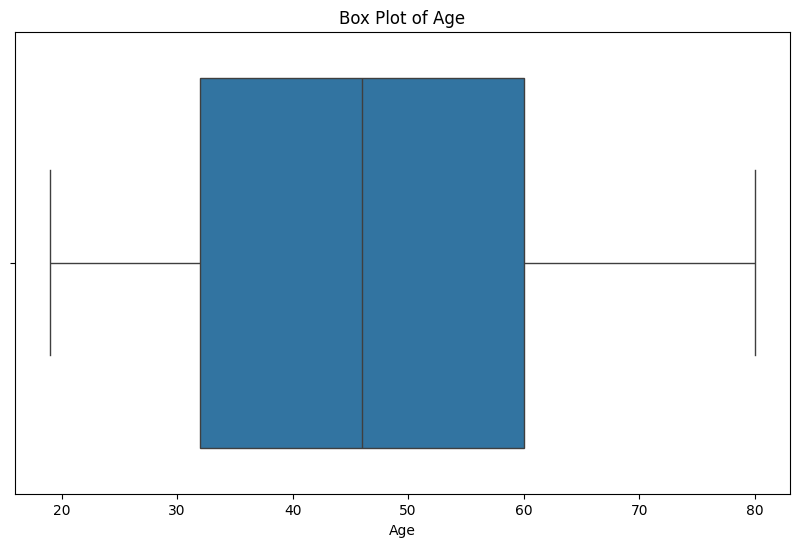

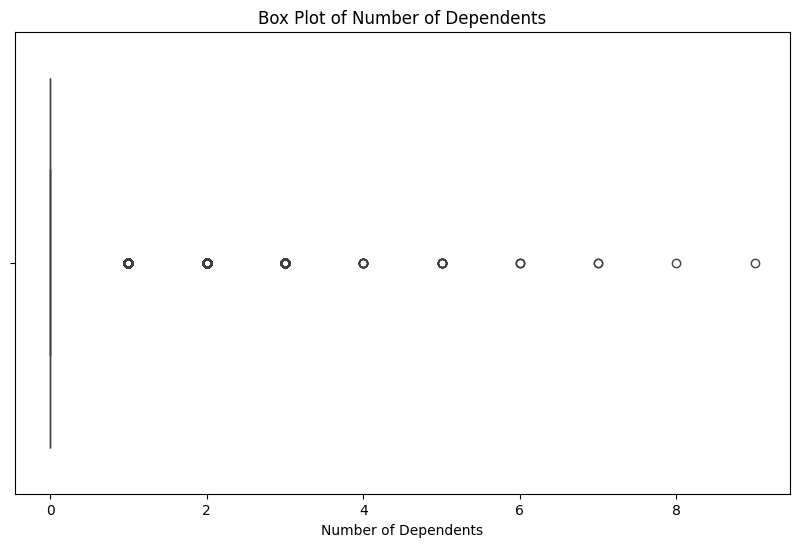

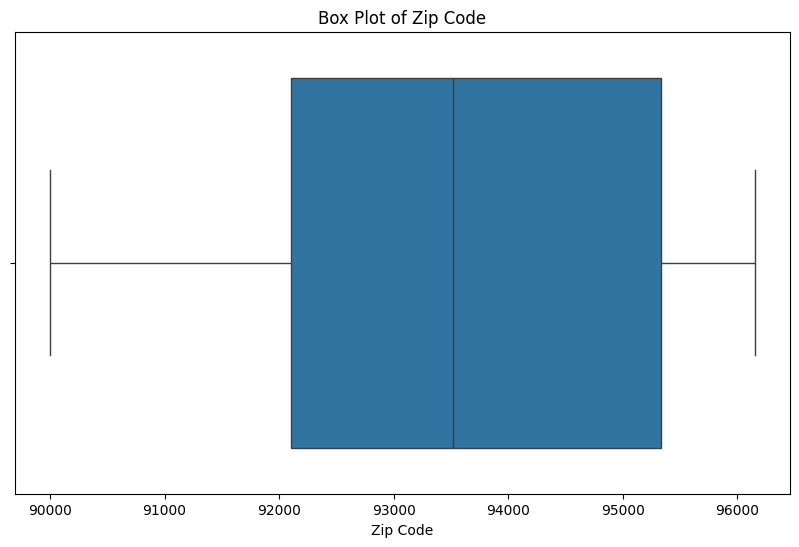

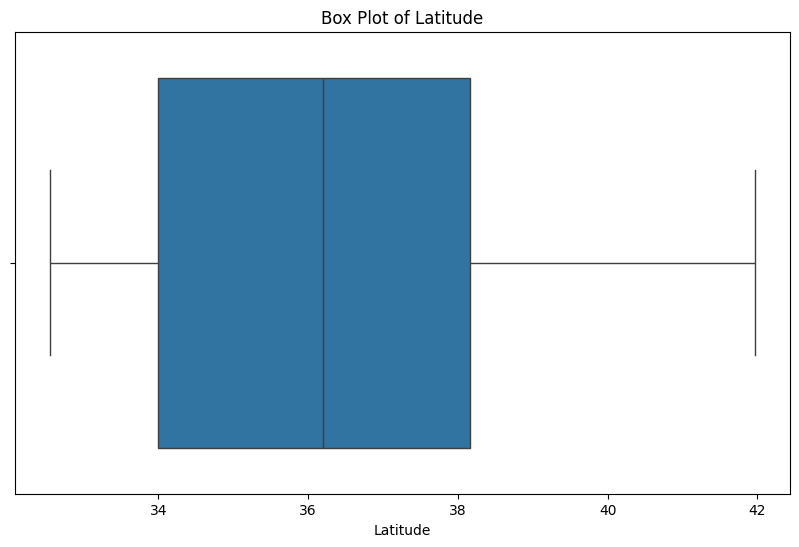

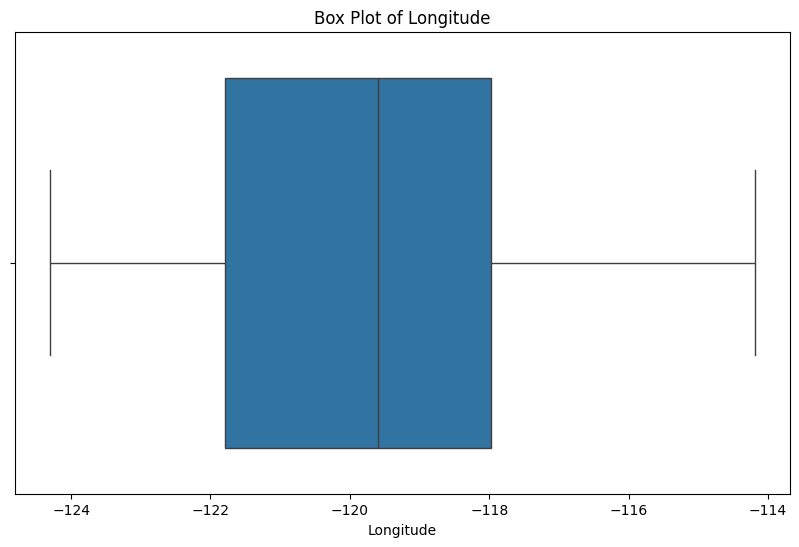

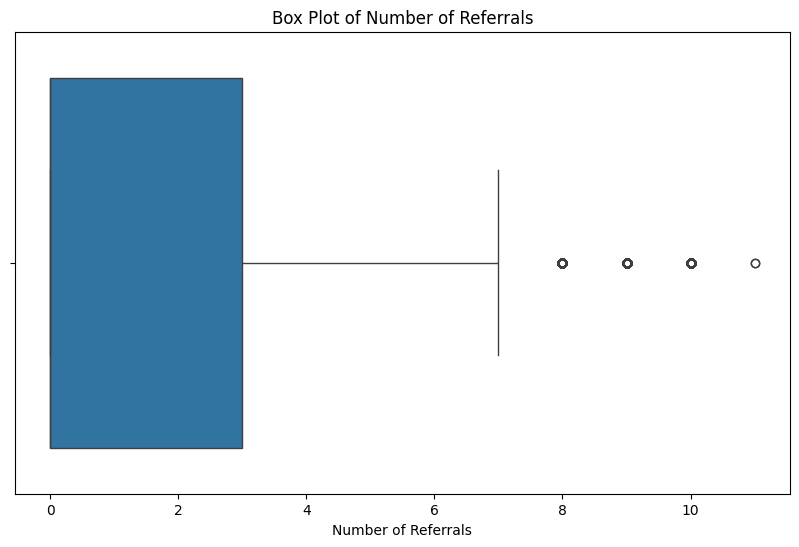

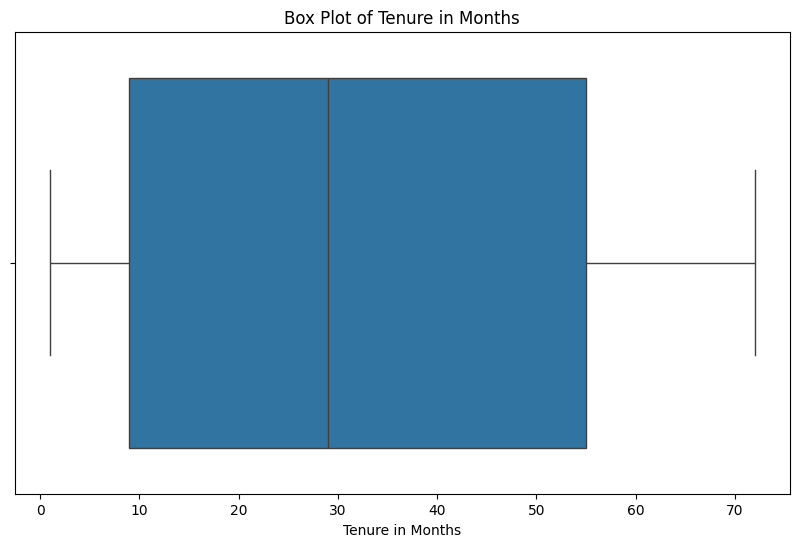

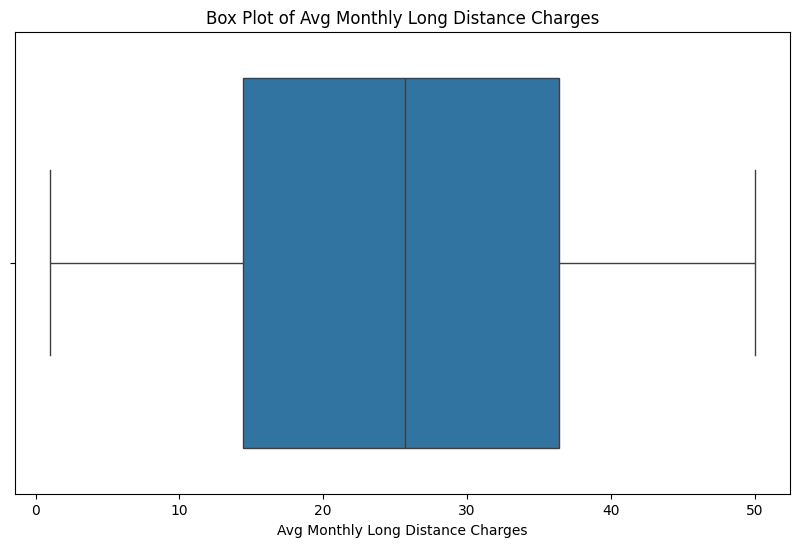

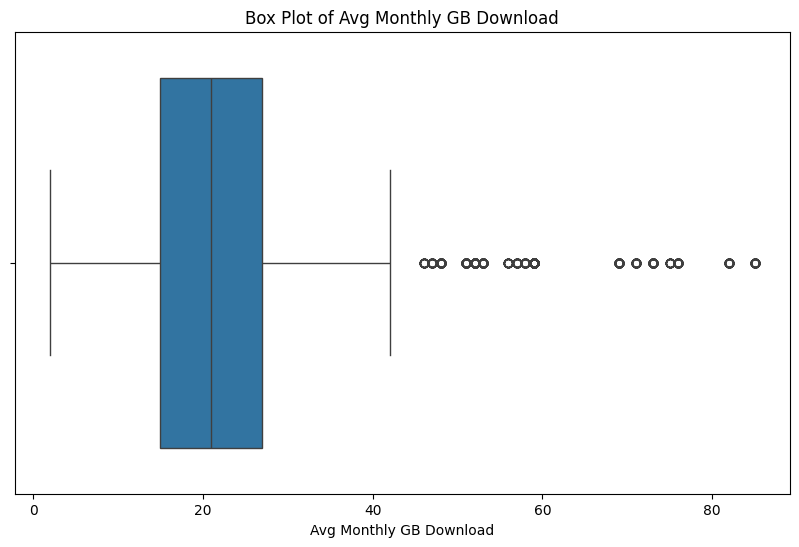

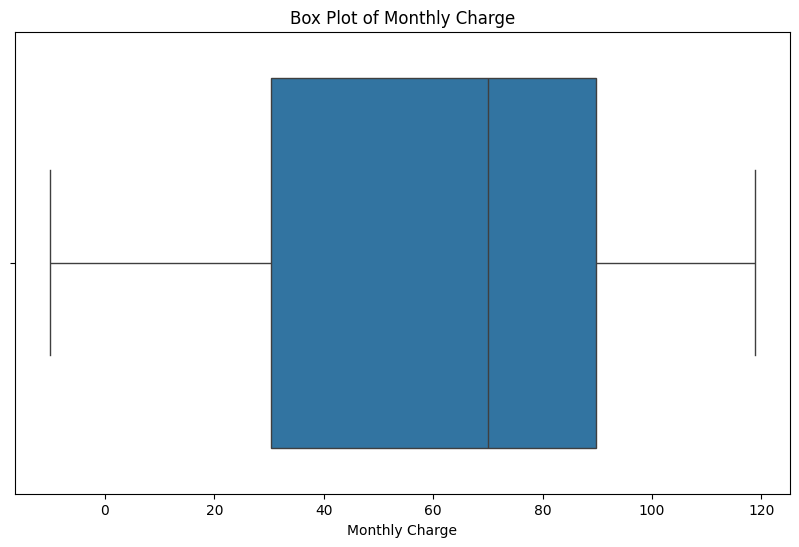

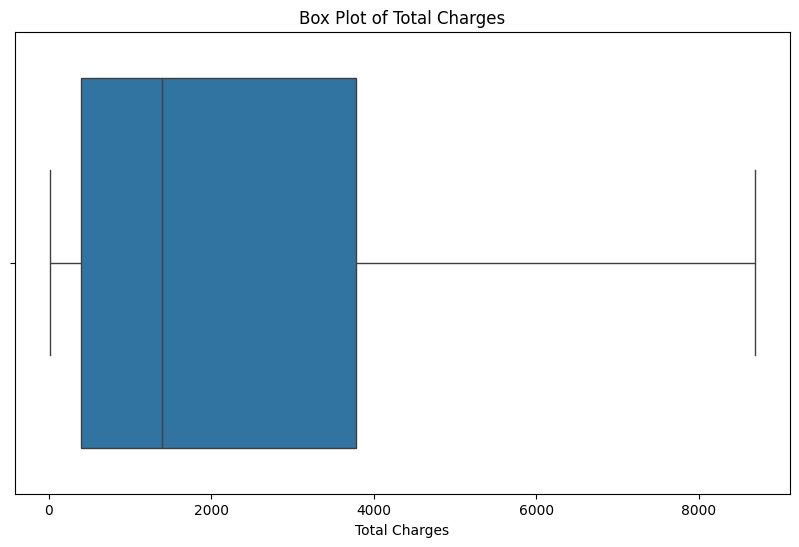

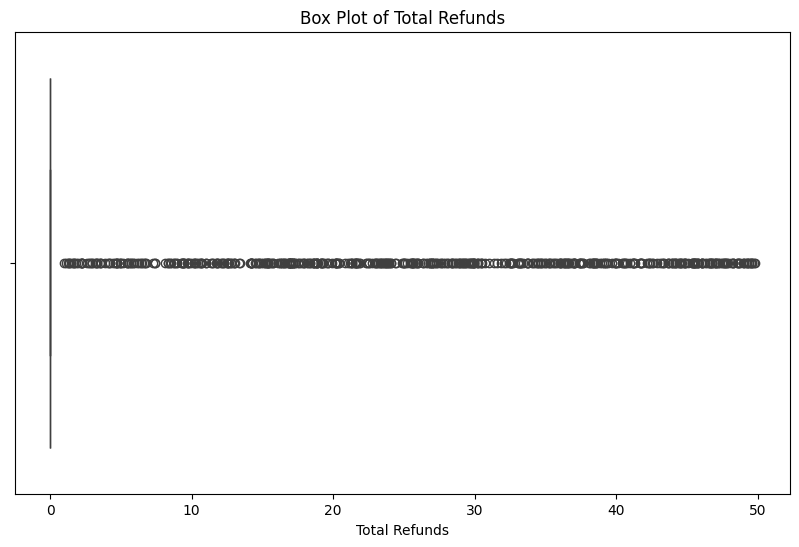

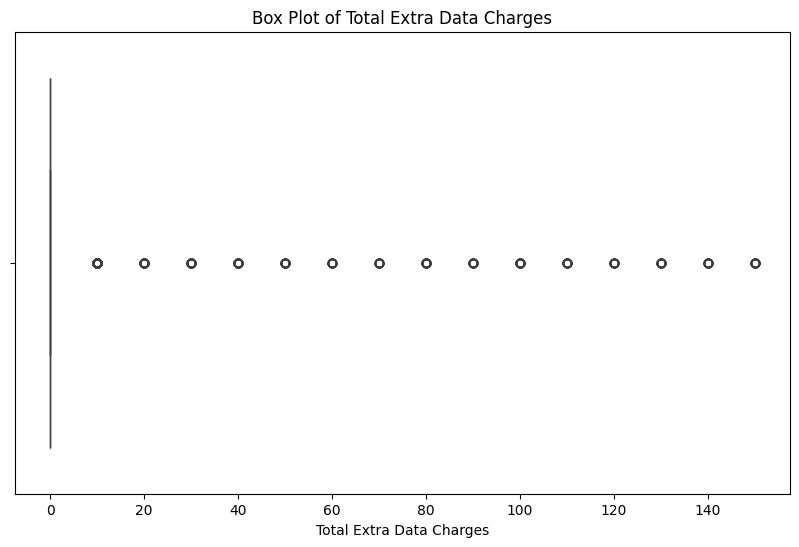

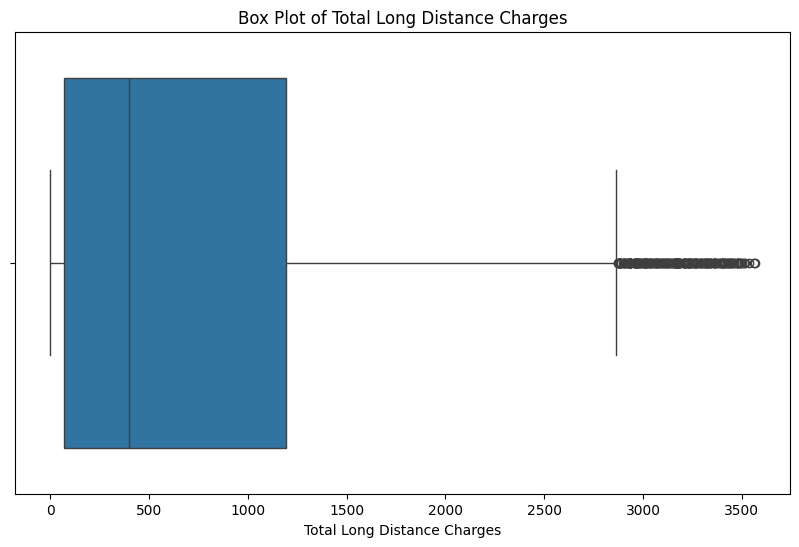

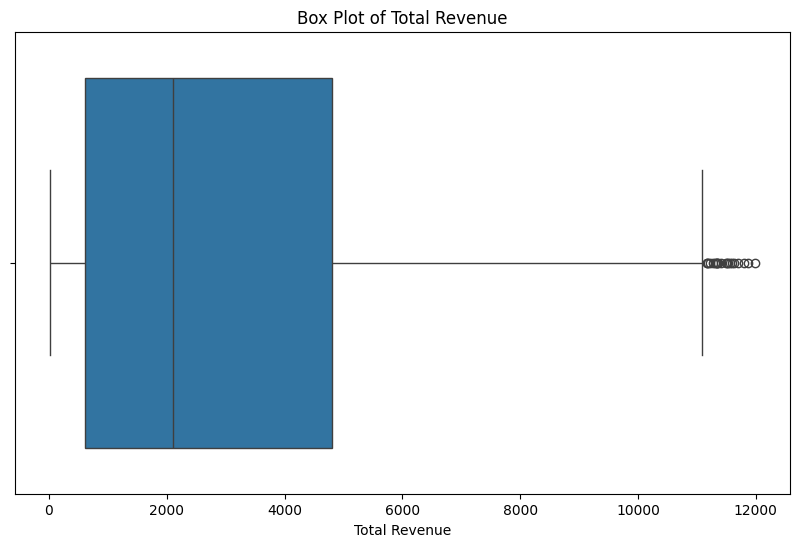

In [171]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [172]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [173]:
# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~(
    (df[numeric_features] < (Q1 - 1.5 * IQR)) |
    (df[numeric_features] > (Q3 + 1.5 * IQR))
).any(axis=1)

df_filtered_numeric = df.loc[condition, numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['str']).columns

df = pd.concat(
    [df_filtered_numeric, df.loc[condition, categorical_features]],
    axis=1
)

In [174]:
from sklearn.preprocessing import StandardScaler
# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

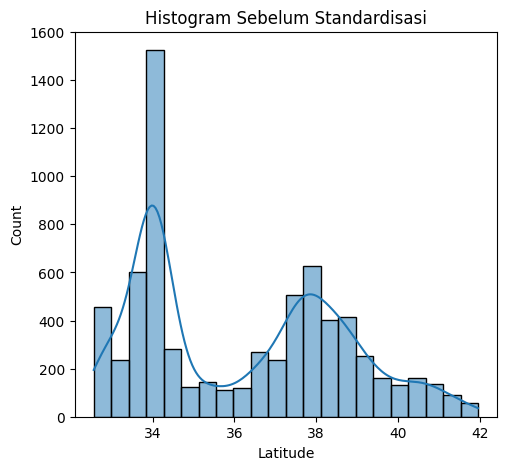

In [175]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

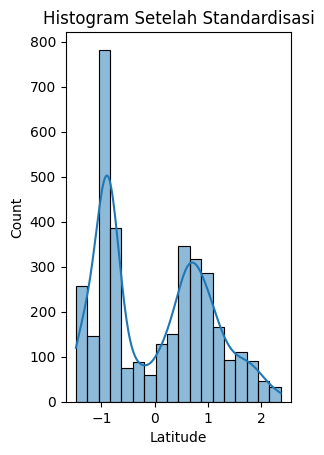

In [176]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")

In [177]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [Age, Number of Dependents, Zip Code, Latitude, Longitude, Number of Referrals, Tenure in Months, Avg Monthly Long Distance Charges, Avg Monthly GB Download, Monthly Charge, Total Charges, Total Refunds, Total Extra Data Charges, Total Long Distance Charges, Total Revenue, Customer ID, Gender, Married, City, Offer, Phone Service, Multiple Lines, Internet Service, Internet Type, Online Security, Online Backup, Device Protection Plan, Premium Tech Support, Streaming TV, Streaming Movies, Streaming Music, Unlimited Data, Contract, Paperless Billing, Payment Method, Customer Status, Churn Category, Churn Reason]
Index: []

[0 rows x 38 columns]


In [178]:
# Menghapus baris duplikat
df = df.drop_duplicates()

print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
           Age  Number of Dependents  Zip Code  Latitude  Longitude  \
0    -0.864941                   0.0 -0.139339 -0.549678   0.348670   
2    -0.037684                   0.0 -0.463128 -1.032968   0.854595   
3     1.744101                   0.0  0.579712  0.753331  -1.115986   
4     1.553195                   0.0 -0.255751 -0.794930   0.310681   
6     1.044114                   0.0 -0.024551 -0.578375  -0.380488   
...        ...                   ...       ...       ...        ...   
7035 -1.946739                   0.0 -1.873615 -0.878355   0.744632   
7036  0.153222                   0.0  0.078867  0.259872   0.394507   
7037 -0.928576                   0.0 -0.787459 -1.148720   1.147383   
7039 -0.674036                   0.0  1.020455  0.639055  -0.570253   
7042 -0.928576                   0.0  1.430877  1.401869  -0.420837   

      Number of Referrals  Tenure in Months  \
0                0.655722         -0.783285   
2              

In [179]:
category_features = df.select_dtypes(include=['str']).columns
df[category_features]

,Customer ID,Gender,Married,City,Offer,Phone Service,Multiple Lines,Internet Service,Internet Type,Online Security,...,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,Yes,Frazier Park,Offer B,Yes,No,Yes,Cable,No,...,Yes,No,No,Yes,One Year,Yes,Credit Card,Stayed,Competitor,Competitor had better devices
2,0004-TLHLJ,Male,No,Costa Mesa,Offer E,Yes,No,Yes,Fiber Optic,No,...,No,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,Yes,Martinez,Offer D,Yes,No,Yes,Fiber Optic,No,...,Yes,Yes,No,Yes,Month-to-Month,Yes,Bank Withdrawal,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,Yes,Camarillo,Offer B,Yes,No,Yes,Fiber Optic,No,...,Yes,No,No,Yes,Month-to-Month,Yes,Credit Card,Churned,Dissatisfaction,Network reliability
6,0013-SMEOE,Female,Yes,Lompoc,Offer A,Yes,No,Yes,Fiber Optic,Yes,...,Yes,Yes,Yes,Yes,Two Year,Yes,Bank Withdrawal,Stayed,Competitor,Competitor had better devices
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7035,9979-RGMZT,Female,No,Los Angeles,Offer E,Yes,No,Yes,Fiber Optic,No,...,Yes,Yes,Yes,Yes,One Year,Yes,Credit Card,Stayed,Competitor,Competitor had better devices
7036,9985-MWVIX,Female,No,Hume,Offer E,Yes,No,Yes,Fiber Optic,No,...,No,No,No,Yes,Month-to-Month,Yes,Credit Card,Churned,Competitor,Competitor had better devices
7037,9986-BONCE,Female,No,Fallbrook,Offer B,Yes,No,No,Fiber Optic,No,...,No,No,No,Yes,Month-to-Month,No,Bank Withdrawal,Churned,Competitor,Competitor made better offer
7039,9992-RRAMN,Male,Yes,Riverbank,Offer D,Yes,Yes,Yes,Fiber Optic,No,...,No,Yes,Yes,Yes,Month-to-Month,Yes,Bank Withdrawal,Churned,Dissatisfaction,Product dissatisfaction


In [180]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

# Menampilkan hasil
df_lencoder

,Age,Number of Dependents,Zip Code,Latitude,Longitude,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,...,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Customer Status,Churn Category,Churn Reason
0,-0.864941,0.0,-0.139339,-0.549678,0.348670,0.655722,-0.783285,1.323627,-0.234229,0.106776,...,1,0,0,1,1,1,1,2,1,2
2,-0.037684,0.0,-0.463128,-1.032968,0.854595,-0.482633,-0.996037,0.666039,1.444538,0.373482,...,0,0,0,1,0,1,0,0,1,2
3,1.744101,0.0,0.579712,0.753331,-1.115986,0.086544,-0.613083,0.227397,-1.673173,1.147894,...,1,1,0,1,0,1,0,0,2,18
4,1.553195,0.0,-0.255751,-0.794930,0.310681,1.224899,-1.038588,-1.310485,-0.833789,0.694815,...,1,0,0,1,0,1,1,0,2,14
6,1.044114,0.0,-0.024551,-0.578375,-0.380488,0.086544,1.854844,-1.116369,-0.474053,1.523853,...,1,1,1,1,2,1,0,2,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7035,-1.946739,0.0,-1.873615,-0.878355,0.744632,-0.482633,-0.868386,0.879718,2.883482,1.020968,...,1,1,1,1,1,1,1,2,1,2
7036,0.153222,0.0,0.078867,0.259872,0.394507,-0.482633,-1.123689,1.301055,-1.073613,0.252982,...,0,0,0,1,0,1,1,0,1,2
7037,-0.928576,0.0,-0.787459,-1.148720,1.147383,-0.482633,-0.996037,-1.714518,0.365330,-1.327975,...,0,0,0,1,0,0,0,0,1,3
7039,-0.674036,0.0,1.020455,0.639055,-0.570253,0.086544,-0.230129,-0.646879,-0.114317,0.733375,...,0,1,1,1,0,1,0,0,2,18


In [181]:
df_lencoder.head()

,Age,Number of Dependents,Zip Code,Latitude,Longitude,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,...,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Customer Status,Churn Category,Churn Reason
0,-0.864941,0.0,-0.139339,-0.549678,0.348670,0.655722,-0.783285,1.323627,-0.234229,0.106776,...,1,0,0,1,1,1,1,2,1,2
2,-0.037684,0.0,-0.463128,-1.032968,0.854595,-0.482633,-0.996037,0.666039,1.444538,0.373482,...,0,0,0,1,0,1,0,0,1,2
3,1.744101,0.0,0.579712,0.753331,-1.115986,0.086544,-0.613083,0.227397,-1.673173,1.147894,...,1,1,0,1,0,1,0,0,2,18
4,1.553195,0.0,-0.255751,-0.794930,0.310681,1.224899,-1.038588,-1.310485,-0.833789,0.694815,...,1,0,0,1,0,1,1,0,2,14
6,1.044114,0.0,-0.024551,-0.578375,-0.380488,0.086544,1.854844,-1.116369,-0.474053,1.523853,...,1,1,1,1,2,1,0,2,1,2


In [182]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

missing_data[missing_data['Missing Values'] > 0]

,Missing Values,Percentage


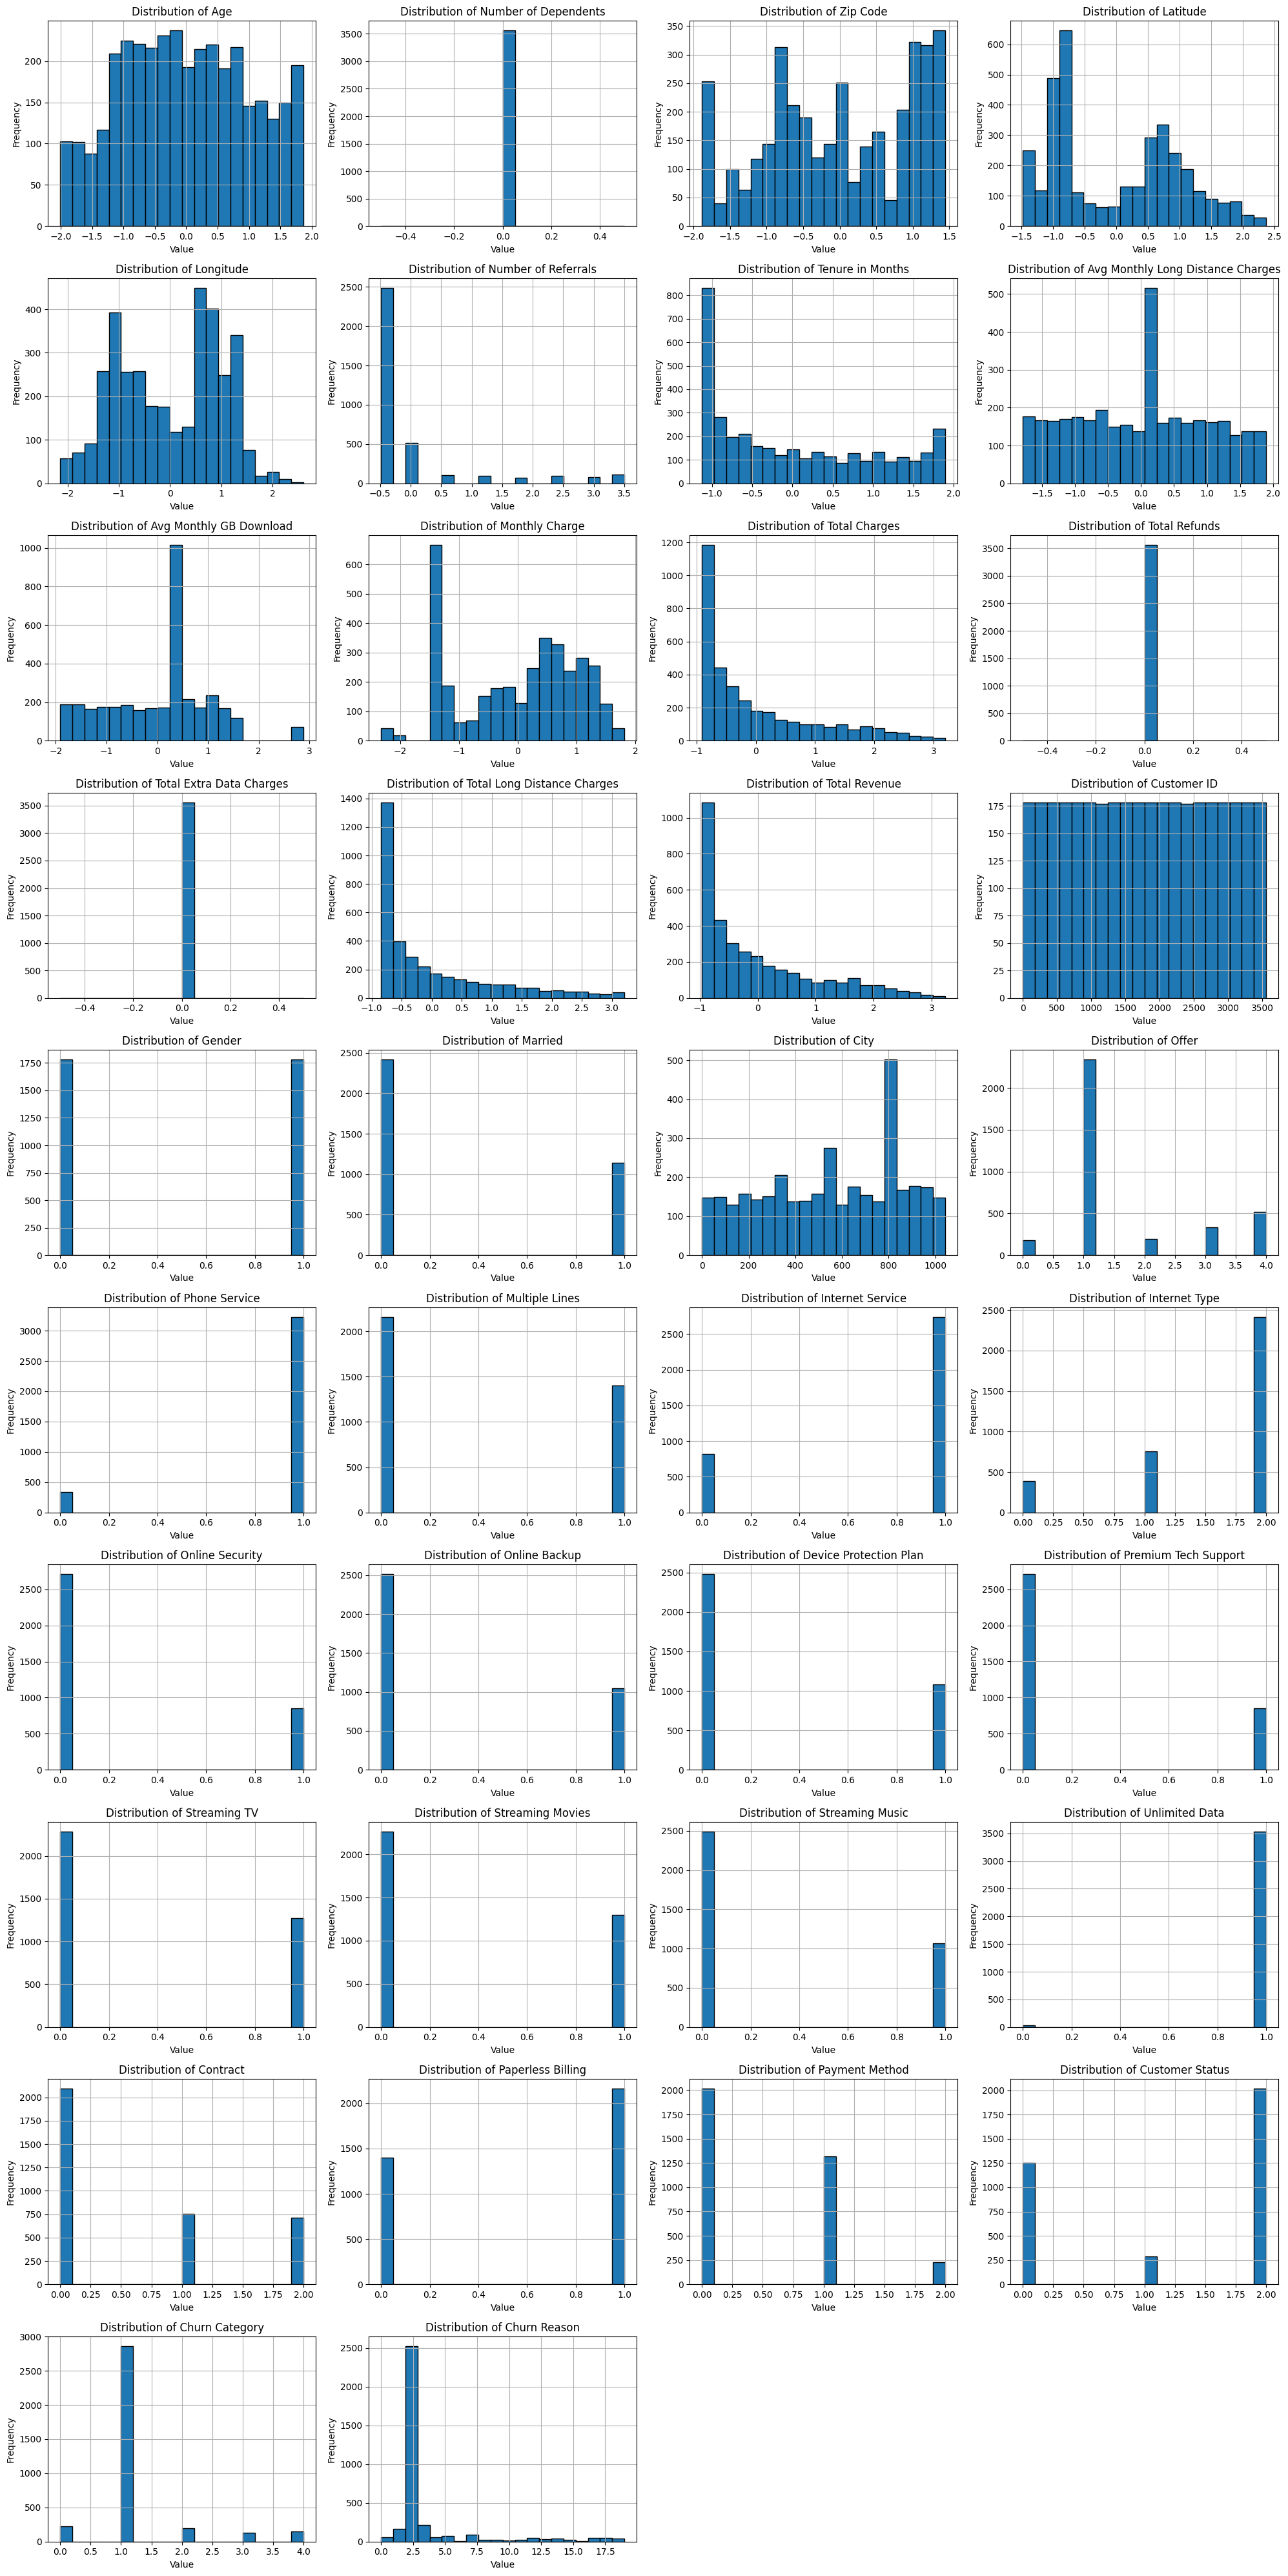

In [183]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4 # Jumlah kolol yang diinginkan 
n_rows = -(-num_vars // n_cols)  # Ceiling division untuk menentukan jumlah baris

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()

# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(
        ax=axes[i],
        bins=20,
        edgecolor='black'
    )
    axes[i].set_title(f'Distribution of {column}')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()

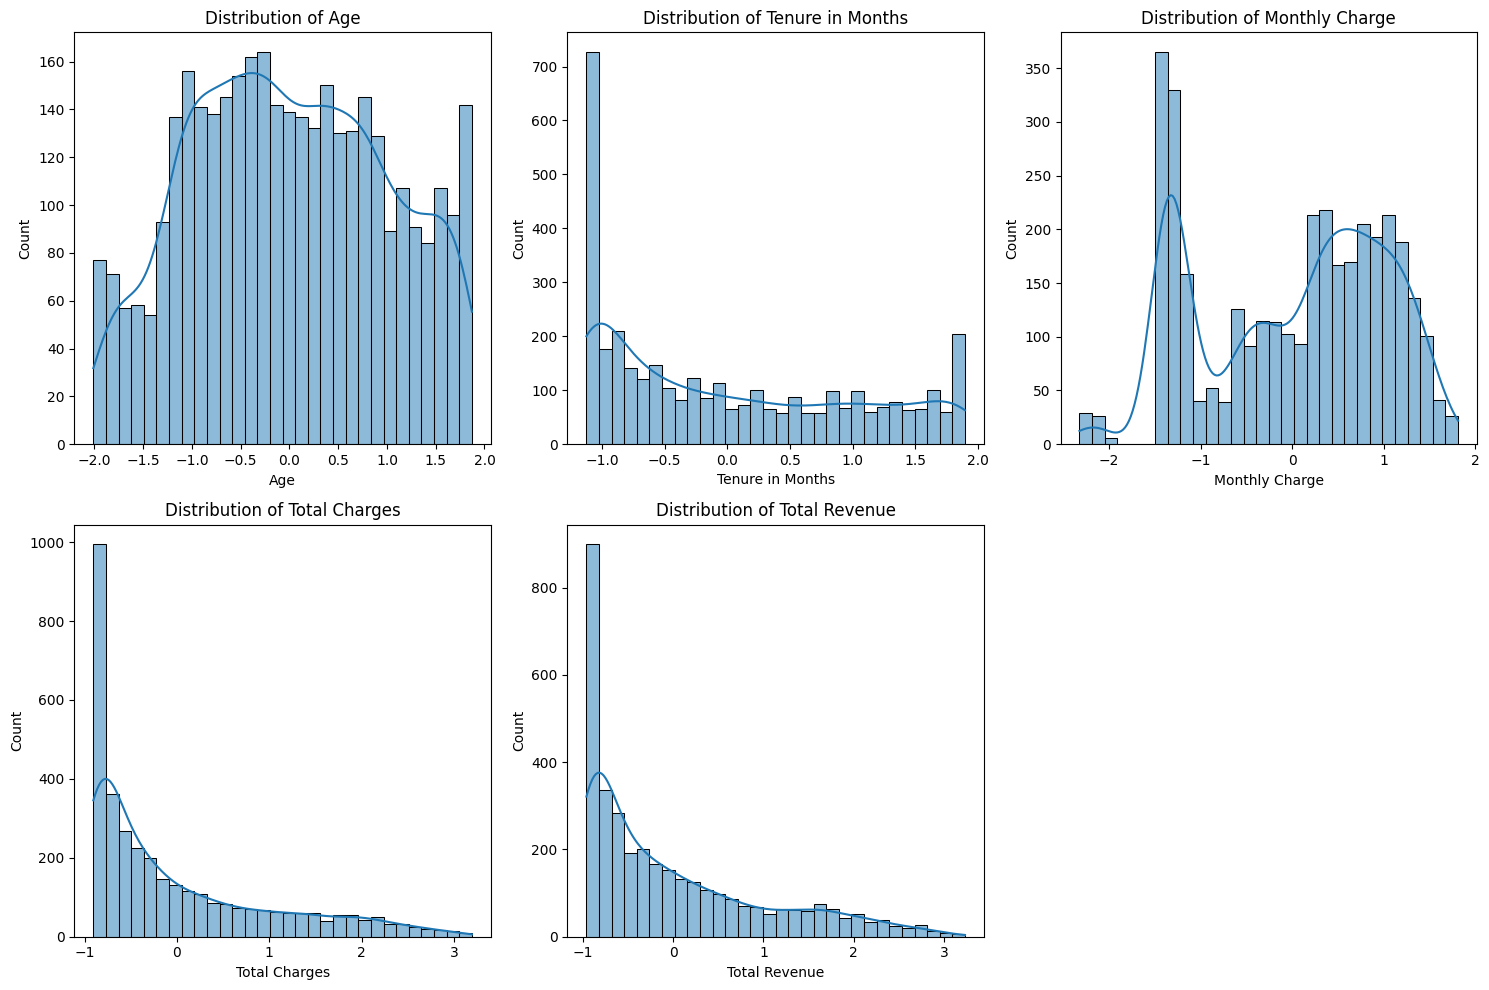

In [184]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi distribusi data untuk beberapa kolom
columns_to_plot = ['Age', 'Tenure in Months', 'Monthly Charge', 'Total Charges', 'Total Revenue']

plt.figure(figsize=(15, 10))

for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

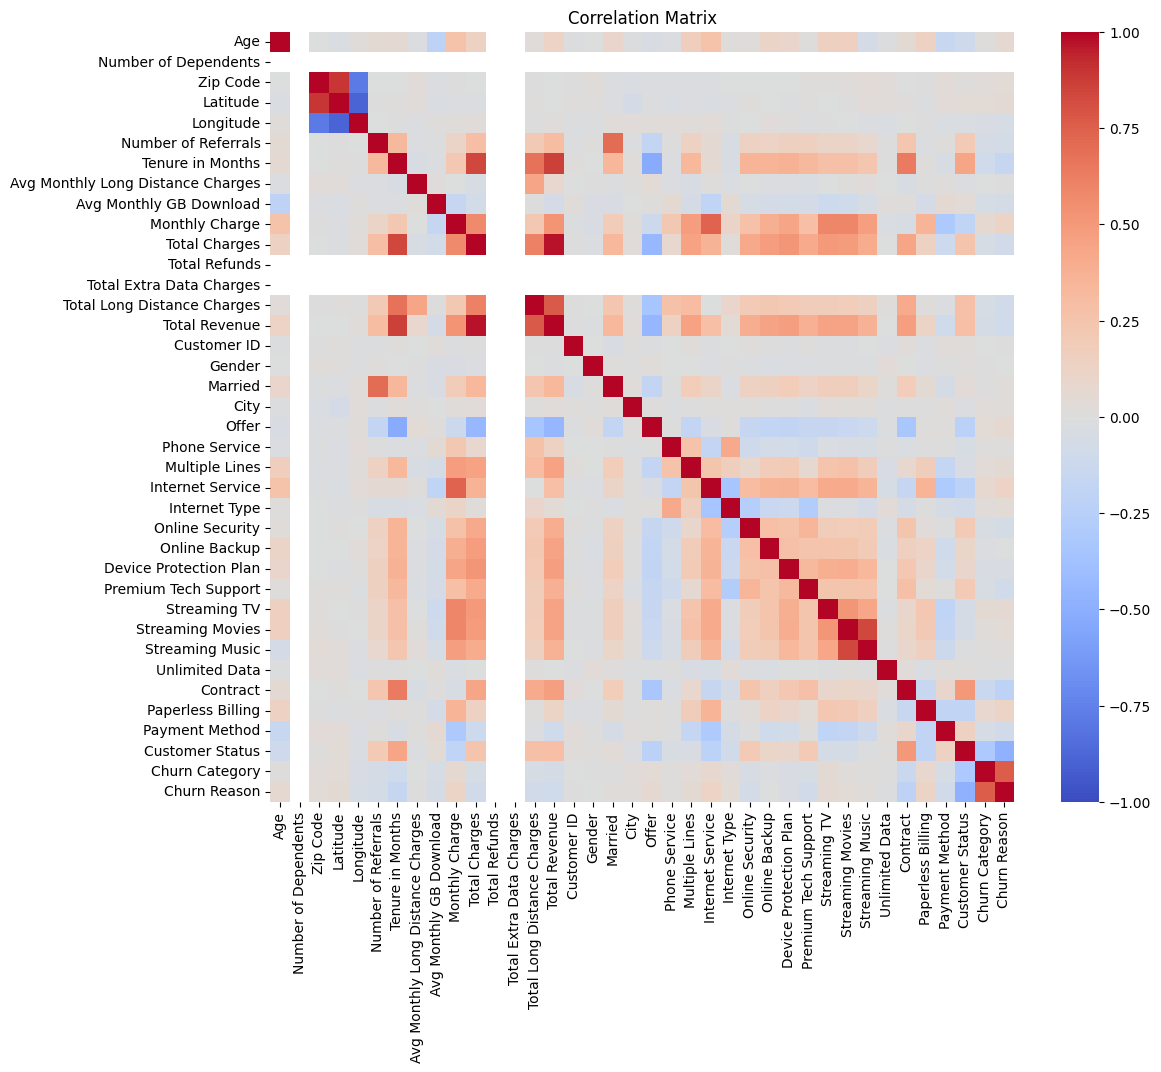

In [185]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

In [186]:
# Membuat variabel target Churn
df_lencoder['Churn'] = (
    df['Customer Status']
    .apply(lambda x: 1 if x == 'Churned' else 0)
)

df_lencoder.head()

,Age,Number of Dependents,Zip Code,Latitude,Longitude,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,...,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Customer Status,Churn Category,Churn Reason,Churn
0,-0.864941,0.0,-0.139339,-0.549678,0.348670,0.655722,-0.783285,1.323627,-0.234229,0.106776,...,0,0,1,1,1,1,2,1,2,0
2,-0.037684,0.0,-0.463128,-1.032968,0.854595,-0.482633,-0.996037,0.666039,1.444538,0.373482,...,0,0,1,0,1,0,0,1,2,1
3,1.744101,0.0,0.579712,0.753331,-1.115986,0.086544,-0.613083,0.227397,-1.673173,1.147894,...,1,0,1,0,1,0,0,2,18,1
4,1.553195,0.0,-0.255751,-0.794930,0.310681,1.224899,-1.038588,-1.310485,-0.833789,0.694815,...,0,0,1,0,1,1,0,2,14,1
6,1.044114,0.0,-0.024551,-0.578375,-0.380488,0.086544,1.854844,-1.116369,-0.474053,1.523853,...,1,1,1,2,1,0,2,1,2,0


In [187]:
X = df_lencoder.drop(columns=['Churn', 'Customer Status', 'Churn Category', 'Churn Reason', 'Customer ID'],
    errors='ignore')

y = df_lencoder['Churn']

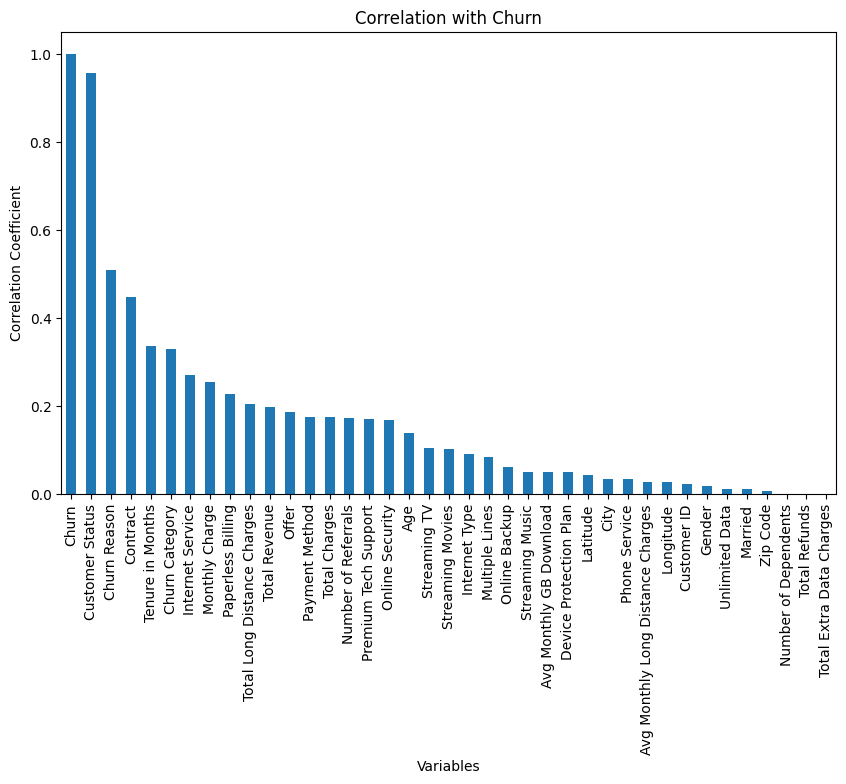

In [188]:
# Menghitung korelasi antara variabel target dan semua variabel lainnya
target_corr = df_lencoder.corr()['Churn']

# Mengurutkan hasil korelasi berdasarkan nilai absolut
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title('Correlation with Churn')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

In [189]:
import sklearn

In [190]:
# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(
    columns=[
        'Churn',
        'Customer Status',
        'Churn Category',
        'Churn Reason',
        'Customer ID'
    ],
    errors='ignore'
)

y = df_lencoder['Churn']

print("Jumlah fitur:", X.shape[1])
print("Jumlah data:", X.shape[0])

Jumlah fitur: 34
Jumlah data: 3558


In [191]:
from sklearn.model_selection import train_test_split

# membagi dataset menjadi training dan testing 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)

In [192]:
# Menghitung panjang/jumlah data
print("Jumlah data: ", len(X))
# Menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ", len(X_train))
# Menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ", len(X_test))

Jumlah data:  3558
Jumlah data latih:  2846
Jumlah data test:  712


In [193]:
print("Distribusi data training:")
print(y_train.value_counts())

print("\nDistribusi data testing:")
print(y_test.value_counts())

Distribusi data training:
Churn
0    1843
1    1003
Name: count, dtype: int64

Distribusi data testing:
Churn
0    461
1    251
Name: count, dtype: int64


In [194]:
# ============================================
# PERBANDINGAN DENGAN MODEL KLASIFIKASI LAIN
# ============================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd


# ============================================
# 1. RANDOM FOREST
# ============================================

model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

model_rf.fit(X_train, y_train)

y_pred_rf = model_rf.predict(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("\n============================================")
print("RANDOM FOREST")
print("============================================")
print(f"Akurasi: {accuracy_rf * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))


# ============================================
# 2. LOGISTIC REGRESSION
# ============================================

model_lr = LogisticRegression(
    max_iter=3000,
    random_state=42,
    class_weight='balanced'
)

model_lr.fit(X_train, y_train)

y_pred_lr = model_lr.predict(X_test)

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("\n============================================")
print("LOGISTIC REGRESSION")
print("============================================")
print(f"Akurasi: {accuracy_lr * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))


# ============================================
# 3. DECISION TREE
# ============================================

model_dt = DecisionTreeClassifier(
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    class_weight='balanced'
)

model_dt.fit(X_train, y_train)

y_pred_dt = model_dt.predict(X_test)

accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("\n============================================")
print("DECISION TREE")
print("============================================")
print(f"Akurasi: {accuracy_dt * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))


# ============================================
# 4. K-NEAREST NEIGHBORS (KNN)
# ============================================

model_knn = KNeighborsClassifier(
    n_neighbors=5
)

model_knn.fit(X_train, y_train)

y_pred_knn = model_knn.predict(X_test)

accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("\n============================================")
print("K-NEAREST NEIGHBORS")
print("============================================")
print(f"Akurasi: {accuracy_knn * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))


# ============================================
# 5. SUPPORT VECTOR MACHINE (SVM)
# ============================================

model_svm = SVC(
    kernel='rbf',
    random_state=42,
    class_weight='balanced'
)

model_svm.fit(X_train, y_train)

y_pred_svm = model_svm.predict(X_test)

accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("\n============================================")
print("SUPPORT VECTOR MACHINE")
print("============================================")
print(f"Akurasi: {accuracy_svm * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))


# ============================================
# 6. PERBANDINGAN AKURASI
# ============================================

hasil_model = pd.DataFrame({
    'Model': [
        'Random Forest',
        'Logistic Regression',
        'Decision Tree',
        'KNN',
        'SVM'
    ],
    'Akurasi': [
        accuracy_rf,
        accuracy_lr,
        accuracy_dt,
        accuracy_knn,
        accuracy_svm
    ]
})


# ============================================
# 7. KONVERSI KE PERSEN
# ============================================

hasil_model['Akurasi (%)'] = hasil_model['Akurasi'] * 100


# ============================================
# 8. URUTKAN DARI AKURASI TERTINGGI
# ============================================

hasil_model = hasil_model.sort_values(
    by='Akurasi',
    ascending=False
)


# ============================================
# 9. TAMPILKAN HASIL
# ============================================

print("\n============================================")
print("PERBANDINGAN AKURASI MODEL")
print("============================================")

print(
    hasil_model[
        ['Model', 'Akurasi (%)']
    ].to_string(index=False)
)


RANDOM FOREST
Akurasi: 81.74%

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.89      0.86       461
           1       0.78      0.68      0.72       251

    accuracy                           0.82       712
   macro avg       0.81      0.79      0.79       712
weighted avg       0.81      0.82      0.81       712


LOGISTIC REGRESSION
Akurasi: 78.37%

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.77      0.82       461
           1       0.65      0.82      0.73       251

    accuracy                           0.78       712
   macro avg       0.77      0.79      0.77       712
weighted avg       0.80      0.78      0.79       712


DECISION TREE
Akurasi: 73.17%

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.75      0.78       461
           1       0.60      0.69      0.65       251

    accurac

In [195]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

# Membangun dan melatih model
GBC = GradientBoostingClassifier(random_state=42)
GBC.fit(X_train, y_train)

# Prediksi pada data pengujian
pred_GBC = GBC.predict(X_test)

# Evaluasi model
print("Accuracy:", accuracy_score(y_test, pred_GBC))
print(classification_report(y_test, pred_GBC))

Accuracy: 0.824438202247191
              precision    recall  f1-score   support

           0       0.86      0.87      0.86       461
           1       0.75      0.75      0.75       251

    accuracy                           0.82       712
   macro avg       0.81      0.81      0.81       712
weighted avg       0.82      0.82      0.82       712



In [196]:
import joblib

# Menyimpan model Random Forest ke dalam file
joblib.dump(model_rf, 'random_forest_model.joblib')

['random_forest_model.joblib']